Import Packages and Useful Function

In [1]:
import pandas as pd
from labtools.adtools import sort
import seaborn as sns
import matplotlib.pyplot as plt
# Function for writing dictionary to csv file (used for loss tables)
import csv
def write_dict_to_csv(file_path, dictionary):
    with open(file_path, 'w', newline='') as csvfile:
        writer = csv.writer(csvfile)
        writer.writerow(dictionary.keys())
        writer.writerow(dictionary.values())
dir = '/global/scratch/projects/fc_mvslab/OpenProjects/Marissa/SynADs/2024-04-00_w.labtoolsDev/2025-10-14_Reprocess/'
name = 'SynAD_Ratio'

Initialize the sort

In [2]:
my_sort = sort.Sort(["/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/rat1_S1.fastq.gz.assembled.fastq", 
                     "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/rat2_S2.fastq.gz.assembled.fastq", 
                     "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/rat3_S3.fastq.gz.assembled.fastq",
                     "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/rat4_S4.fastq.gz.assembled.fastq",
                     "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/rat5_S5.fastq.gz.assembled.fastq",
                     "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/rat6_S6.fastq.gz.assembled.fastq",
                     "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/rat7_S7.fastq.gz.assembled.fastq",
                     "/global/scratch/projects/fc_mvslab/data/sequencing/CZB_Apr2024/20240425/MZ_SynADs/results/rat8_S8.fastq.gz.assembled.fastq"], 
                    bin_counts = [1000000,1000000,1000000,1000000,1000000,1000000,1000000,800000], 
                    bin_values = [5815,17690,32080,51502,81489,125567,194220,262143], 
                    design_file = "/global/scratch/projects/fc_mvslab/OpenProjects/Marissa/DesignFiles/PlantSynADs_Design.csv")

Process

In [3]:
activities, total_reads, reads_per_bin, loss_table = my_sort.process(thresh=39, ad_preceder = "GCTAGC", bc_preceder = "GGGCCCG", 
            bc_anteceder = "GGCGCGCC", ad_length = 120, bclength = 14, barcoded = True)

Opening file rat1_S1.fastq.gz.assembled.fastq ...
Total parsed reads = 3,817,947                      
Opening file rat2_S2.fastq.gz.assembled.fastq ...
Total parsed reads = 2,575,162                      
Opening file rat3_S3.fastq.gz.assembled.fastq ...
Total parsed reads = 2,470,667                      
Opening file rat4_S4.fastq.gz.assembled.fastq ...
Total parsed reads = 5,883,962                      
Opening file rat5_S5.fastq.gz.assembled.fastq ...
Total parsed reads = 3,387,755                      
Opening file rat6_S6.fastq.gz.assembled.fastq ...
Total parsed reads = 4,996,240                      
Opening file rat7_S7.fastq.gz.assembled.fastq ...
Total parsed reads = 4,592,746                      
Opening file rat8_S8.fastq.gz.assembled.fastq ...
Total parsed reads = 6,439,124                      


Outputs

In [4]:
loss_table

{'ad_preceder': 136653,
 'design_file': 1988570.0,
 'thresh': 307646.0,
 'bc_is_na': 2458.0,
 'bc_flanks': 106877,
 'bc_length': 25640}

In [5]:
# Convert Series of tuples to DataFrame with two columns
total_reads_df = total_reads.apply(pd.Series)
# Reset index to convert the tuple index into columns
total_reads_df = total_reads.reset_index()
# Rename the columns
total_reads_df.columns = ['AD', 'BC', 'Reads']
# Count the occurrences of each 'BC' and create a new Series
bc_counts = total_reads_df['BC'].value_counts()
# Assign the counts back to the original DataFrame
total_reads_df['ADs_per_BC'] = total_reads_df['BC'].map(bc_counts)
# Similarly, count the occurrences of each 'AD' and create a new Series
ad_counts = total_reads_df['AD'].value_counts()
# Assign the counts back to the original DataFrame
total_reads_df['BCs_per_AD'] = total_reads_df['AD'].map(ad_counts)
# Sum all the reads that have the same sequence in the 'AD' column
total_reads_df['numreads_per_AD'] = total_reads_df.groupby('AD')['Reads'].transform('sum')

activities.reset_index(inplace=True)
# Rename the columns for clarity
activities.rename(columns={'level_0': 'DNAseq', 'level_1': 'BC'}, inplace=True)
activities

,DNAseq,BC,0,1,2,3,4,5,6,7,Activity
0,ATTGGTTCTTTTGATGCTTCTCAACCACAATTTTTGGCTGATGATG...,GAAGAATAGATTAT,0.788899,0.176224,0.031489,0.000000,0.0,0.001737,0.001652,0.000000,9253.849020
1,ATGGTTAAAATTGAAGAAGAATTTCCAGATTTTGCTGATCATGGTG...,TGAAACTTTGCTAA,0.448962,0.463240,0.066248,0.021550,0.0,0.000000,0.000000,0.000000,14040.524656
2,TCTTCTGAAGATAATTGTTTTCAAGATGCTGCTGAATTGGAAGATG...,AGGAAGATACCTTT,0.642118,0.296784,0.061099,0.000000,0.0,0.000000,0.000000,0.000000,10944.066383
3,CAAGCTGAATTGTTGGAAAATTTGTGGTTGGGTACTTTGTTGCCAT...,CTAAATCAGCAAAC,0.933246,0.057235,0.003928,0.005404,0.0,0.000000,0.000000,0.000187,6892.695508
4,ACTTGTCCATCTGCTTTGCCAGATTTTACTACTGTTGGTGATTTTT...,ACTTATAGTAGTTA,0.656016,0.286861,0.042618,0.000000,0.0,0.000000,0.000000,0.014505,14058.963138
...,...,...,...,...,...,...,...,...,...,...,...
43327,TCTTTGGAAACTATTACTTTGAATGAATTGTTGGGTATTTTGGATT...,GCTGACGACTATAG,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,1.000000,262143.000000
43328,GTTGGTGATGTTGGTATTCCAACTTTGCCAGATTTTTCTGGTGATT...,GCCGGAGAAATAAT,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,1.000000,262143.000000
43329,ATGGAATGTGTTGAAGCTTTTTTGGGTGATTTTTCTGTTGATGATT...,GTCCCATTGAGGGG,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,1.000000,262143.000000
43330,CATGGTAATGTTTTGAATGATGAATGGTCTTTTGAAGTTTTTTTTC...,AGTCAGAGCGGTAA,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,1.000000,262143.000000


QC Analyses

In [6]:
print(total_reads_df.shape, activities.shape)

(43332, 6) (43332, 11)


In [7]:
activities.head(10)

,DNAseq,BC,0,1,2,3,4,5,6,7,Activity
0,ATTGGTTCTTTTGATGCTTCTCAACCACAATTTTTGGCTGATGATG...,GAAGAATAGATTAT,0.788899,0.176224,0.031489,0.000000,0.000000,0.001737,0.001652,0.000000,9253.849020
1,ATGGTTAAAATTGAAGAAGAATTTCCAGATTTTGCTGATCATGGTG...,TGAAACTTTGCTAA,0.448962,0.463240,0.066248,0.021550,0.000000,0.000000,0.000000,0.000000,14040.524656
2,TCTTCTGAAGATAATTGTTTTCAAGATGCTGCTGAATTGGAAGATG...,AGGAAGATACCTTT,0.642118,0.296784,0.061099,0.000000,0.000000,0.000000,0.000000,0.000000,10944.066383
3,CAAGCTGAATTGTTGGAAAATTTGTGGTTGGGTACTTTGTTGCCAT...,CTAAATCAGCAAAC,0.933246,0.057235,0.003928,0.005404,0.000000,0.000000,0.000000,0.000187,6892.695508
4,ACTTGTCCATCTGCTTTGCCAGATTTTACTACTGTTGGTGATTTTT...,ACTTATAGTAGTTA,0.656016,0.286861,0.042618,0.000000,0.000000,0.000000,0.000000,0.014505,14058.963138
5,TCTGCTACTACTTCTACTCATCAAGTTTTTGATTATGCTGATGATG...,ACTTCGTAAAAATA,0.658661,0.303338,0.027632,0.010368,0.000000,0.000000,0.000000,0.000000,10616.602960
6,TCTGATAAAACTTTTTTGGATTTTTCTGAAGGTCAAAAAGAAGAAG...,GGAAGATGAACATG,0.815374,0.148028,0.028047,0.008552,0.000000,0.000000,0.000000,0.000000,8700.179881
7,AAATCTTCTACTTTGCCAAATACTGTTACTGAAGAATTGGGTCAAA...,GGATGAAGGAAATG,0.414906,0.441578,0.118005,0.025511,0.000000,0.000000,0.000000,0.000000,15323.663728
8,AGAGAAGATGTTTATGATGAAGATTTGTCTCCATTTTATGATCATG...,AAATGTATACAGCC,0.597824,0.338625,0.063550,0.000000,0.000000,0.000000,0.000000,0.000000,11505.327105
9,GGTTCTTTGGTTTTGGGTTCTTTGGATTTTGGTCATGTTGAAGATG...,ATTTACTATTTTGA,0.172798,0.352532,0.185739,0.231602,0.021155,0.035354,0.000000,0.000819,31505.614610


In [8]:
total_reads_df.head(10)

,AD,BC,Reads,ADs_per_BC,BCs_per_AD,numreads_per_AD
0,ATTGGTTCTTTTGATGCTTCTCAACCACAATTTTTGGCTGATGATG...,GAAGAATAGATTAT,3062.0,1.0,3,4473.0
1,ATGGTTAAAATTGAAGAAGAATTTCCAGATTTTGCTGATCATGGTG...,TGAAACTTTGCTAA,1707.0,1.0,1,1707.0
2,TCTTCTGAAGATAATTGTTTTCAAGATGCTGCTGAATTGGAAGATG...,AGGAAGATACCTTT,127.0,1.0,4,853.0
3,CAAGCTGAATTGTTGGAAAATTTGTGGTTGGGTACTTTGTTGCCAT...,CTAAATCAGCAAAC,3623.0,1.0,3,4457.0
4,ACTTGTCCATCTGCTTTGCCAGATTTTACTACTGTTGGTGATTTTT...,ACTTATAGTAGTTA,432.0,1.0,7,2574.0
5,TCTGCTACTACTTCTACTCATCAAGTTTTTGATTATGCTGATGATG...,ACTTCGTAAAAATA,476.0,1.0,4,2445.0
6,TCTGATAAAACTTTTTTGGATTTTTCTGAAGGTCAAAAAGAAGAAG...,GGAAGATGAACATG,3291.0,1.0,4,8114.0
7,AAATCTTCTACTTTGCCAAATACTGTTACTGAAGAATTGGGTCAAA...,GGATGAAGGAAATG,282.0,1.0,2,735.0
8,AGAGAAGATGTTTATGATGAAGATTTGTCTCCATTTTATGATCATG...,AAATGTATACAGCC,662.0,1.0,4,2065.0
9,GGTTCTTTGGTTTTGGGTTCTTTGGATTTTGGTCATGTTGAAGATG...,ATTTACTATTTTGA,847.0,1.0,2,1310.0


In [9]:
print('sum included reads: ', total_reads_df['Reads'].sum())
total_sum = total_reads_df['Reads'].sum() + loss_table['ad_preceder'] + loss_table['design_file'] + loss_table['thresh']
print('% included reads: ', 100*total_reads_df['Reads'].sum() / total_sum)
print('% reads lost ad_preceder: ', 100*loss_table['ad_preceder'] / total_sum)
print('% reads lost design_file: ', 100*loss_table['design_file'] / total_sum)
print('% reads lost thresh: ', 100*loss_table['thresh'] / total_sum)
total_reads

sum included reads:  31730734.0
% included reads:  92.87876925627546
% reads lost ad_preceder:  0.3999958669464693
% reads lost design_file:  5.8207268126842475
% reads lost thresh:  0.9005080640938252


ATTGGTTCTTTTGATGCTTCTCAACCACAATTTTTGGCTGATGATGATTCTTATGTTACTCAATCTTTGTTTTTTTGGGAATTGAGATTTAGATTTTCTCCAGAAAATTTTGATATTCAA  GAAGAATAGATTAT    3062.0
ATGGTTAAAATTGAAGAAGAATTTCCAGATTTTGCTGATCATGGTGATTTGTTGGATTTTTCTAATGAAGATATTTTTTCTGCTTCTTCTGCTGCTAATTCTGATTATTTTTCTGATTTG  TGAAACTTTGCTAA    1707.0
TCTTCTGAAGATAATTGTTTTCAAGATGCTGCTGAATTGGAAGATGGTAATTTGGATGAATTGGAATCTGATATGATTGATATGGCTGTTTTTGATGATTCTTTTCCAAATGCTGAAGTT  AGGAAGATACCTTT     127.0
CAAGCTGAATTGTTGGAAAATTTGTGGTTGGGTACTTTGTTGCCATCTTTGTTGGAAGATTTGGATGGTGATGATTTGTTGGAAGAAGAAAGAGAAAGACAAGAATCTGATGAAGTTATG  CTAAATCAGCAAAC    3623.0
ACTTGTCCATCTGCTTTGCCAGATTTTACTACTGTTGGTGATTTTTTGGCTTCTTTTTTGGATTTGTTGCCAATGAATTTTGGTTTTGGTGATATTTTGCAATTTCATGGTTCTTCTACT  ACTTATAGTAGTTA     432.0
                                                                                                                                             ...  
TCTTTGGAAACTATTACTTTGAATGAATTGTTGGGTATTTTGGATTTGGATTATCCAACTGAATTTTTGTCTATGCCATTGTTGTCTGATAATGATGATTGTTTGGGTGGTTTTCATT

Saving Data

In [10]:
# Make combined dataframe with: DNAseq, AAseq, total reads, readsperbin, activity
merge = activities.merge(total_reads_df, left_index=True, right_index=True)
are_columns_equal = merge['DNAseq'].equals(merge['AD'])
print('activities and reads columns are equal for AD :', are_columns_equal)
merge = merge.drop(columns=[0, 1, 2, 3, 4, 5, 6, 7, 'AD'])
reads_per_bin.index.names = ['AD', 'BC']
reads_per_bin.columns = [0, 1, 2, 3, 4, 5, 6, 7]
reads_per_bin_reset = reads_per_bin.reset_index()
merge2 = merge.merge(reads_per_bin_reset, left_index=True, right_index=True) # changed to filter on index instead of column
are_columns_equal2 = merge2['DNAseq'].equals(merge2['AD'])
print(are_columns_equal2)
merge2.drop(columns=['AD'], inplace=True)
# Translates DNA sequences (in column labelled "DNAseq") to amino acid sequences and adds those in "AAseq" column
def translate_seq(df):

    # Define the translation table
    table = {
        'ATA':'I', 'ATC':'I', 'ATT':'I', 'ATG':'M',
        'ACA':'T', 'ACC':'T', 'ACG':'T', 'ACT':'T',
        'AAC':'N', 'AAT':'N', 'AAA':'K', 'AAG':'K',
        'AGC':'S', 'AGT':'S', 'AGA':'R', 'AGG':'R',
        'CTA':'L', 'CTC':'L', 'CTG':'L', 'CTT':'L',
        'CCA':'P', 'CCC':'P', 'CCG':'P', 'CCT':'P',
        'CAC':'H', 'CAT':'H', 'CAA':'Q', 'CAG':'Q',
        'CGA':'R', 'CGC':'R', 'CGG':'R', 'CGT':'R',
        'GTA':'V', 'GTC':'V', 'GTG':'V', 'GTT':'V',
        'GCA':'A', 'GCC':'A', 'GCG':'A', 'GCT':'A',
        'GAC':'D', 'GAT':'D', 'GAA':'E', 'GAG':'E',
        'GGA':'G', 'GGC':'G', 'GGG':'G', 'GGT':'G',
        'TCA':'S', 'TCC':'S', 'TCG':'S', 'TCT':'S',
        'TTC':'F', 'TTT':'F', 'TTA':'L', 'TTG':'L',
        'TAC':'Y', 'TAT':'Y', 'TAA':'_', 'TAG':'_',
        'TGC':'C', 'TGT':'C', 'TGA':'_', 'TGG':'W',
    }

    # List to store translated protein sequences
    protein_list = []

    # Translate each DNA sequence in the list
    for dnaseq in df["DNAseq"]:
        protein = ""

        # Check if the length of the DNA sequence is divisible by 3
        if len(dnaseq) % 3 == 0:
            # Iterate over the DNA sequence in steps of 3
            for i in range(0, 119, 3):
                # Extract a codon from the DNA sequence
                codon = dnaseq[i:i + 3]
                # Lookup the amino acid corresponding to the codon and append it to the protein sequence
                protein += table.get(codon, '')

        # Append the translated protein sequence to the list
        protein_list.append(protein)
    # Add a new column to the DataFrame with the translated protein sequences
    df["AAseq"] = protein_list

    return df
merge2 = translate_seq(merge2)
merge2 = merge2.reindex(columns=['DNAseq', 'AAseq', 'BC', 'Reads', 0, 1, 2, 3, 4, 5, 6, 7, 'Activity', 'ADs_per_BC', 'BCs_per_AD', 'numreads_per_AD'])

activities and reads columns are equal for AD : True
True


In [11]:
merge2

,DNAseq,AAseq,BC,Reads,0,1,2,3,4,5,6,7,Activity,ADs_per_BC,BCs_per_AD,numreads_per_AD
0,ATTGGTTCTTTTGATGCTTCTCAACCACAATTTTTGGCTGATGATG...,IGSFDASQPQFLADDDSYVTQSLFFWELRFRFSPENFDIQ,GAAGAATAGATTAT,3062.0,2567.0,409.0,71.0,0.0,0.0,8.0,7.0,0.0,9253.849020,1.0,3,4473.0
1,ATGGTTAAAATTGAAGAAGAATTTCCAGATTTTGCTGATCATGGTG...,MVKIEEEFPDFADHGDLLDFSNEDIFSASSAANSDYFSDL,TGAAACTTTGCTAA,1707.0,890.0,655.0,91.0,71.0,0.0,0.0,0.0,0.0,14040.524656,1.0,1,1707.0
2,TCTTCTGAAGATAATTGTTTTCAAGATGCTGCTGAATTGGAAGATG...,SSEDNCFQDAAELEDGNLDELESDMIDMAVFDDSFPNAEV,AGGAAGATACCTTT,127.0,91.0,30.0,6.0,0.0,0.0,0.0,0.0,0.0,10944.066383,1.0,4,853.0
3,CAAGCTGAATTGTTGGAAAATTTGTGGTTGGGTACTTTGTTGCCAT...,QAELLENLWLGTLLPSLLEDLDGDDLLEEERERQESDEVM,CTAAATCAGCAAAC,3623.0,3429.0,150.0,10.0,33.0,0.0,0.0,0.0,1.0,6892.695508,1.0,3,4457.0
4,ACTTGTCCATCTGCTTTGCCAGATTTTACTACTGTTGGTGATTTTT...,TCPSALPDFTTVGDFLASFLDLLPMNFGFGDILQFHGSST,ACTTATAGTAGTTA,432.0,311.0,97.0,14.0,0.0,0.0,0.0,0.0,10.0,14058.963138,1.0,7,2574.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43327,TCTTTGGAAACTATTACTTTGAATGAATTGTTGGGTATTTTGGATT...,SLETITLNELLGILDLDYPTEFLSMPLLSDNDDCLGGFHL,GCTGACGACTATAG,50.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,50.0,262143.000000,1.0,2,574.0
43328,GTTGGTGATGTTGGTATTCCAACTTTGCCAGATTTTTCTGGTGATT...,VGDVGIPTLPDFSGDFTEFEDILFSELFHDWVYDVIKNDL,GCCGGAGAAATAAT,42.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,42.0,262143.000000,1.0,1,42.0
43329,ATGGAATGTGTTGAAGCTTTTTTGGGTGATTTTTCTGTTGATGATT...,MECVEAFLGDFSVDDFSVDDFSVDDFSVDDLWPMNIYNGN,GTCCCATTGAGGGG,87.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,87.0,262143.000000,1.0,6,8179.0
43330,CATGGTAATGTTTTGAATGATGAATGGTCTTTTGAAGTTTTTTTTC...,HGNVLNDEWSFEVFFPSPEIVQSPISPFLVDELLQEFLPQ,AGTCAGAGCGGTAA,50.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,50.0,262143.000000,1.0,3,2335.0


In [12]:
reads_per_bin.to_csv(f"{dir}/DataFiles/{name}_readsperbin.csv", index=True)
write_dict_to_csv(f'{dir}/DataFiles/{name}_loss.csv', loss_table)
merge2.to_csv(f'{dir}/DataFiles/{name}_allinfo.csv', index=True)

Graphing

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


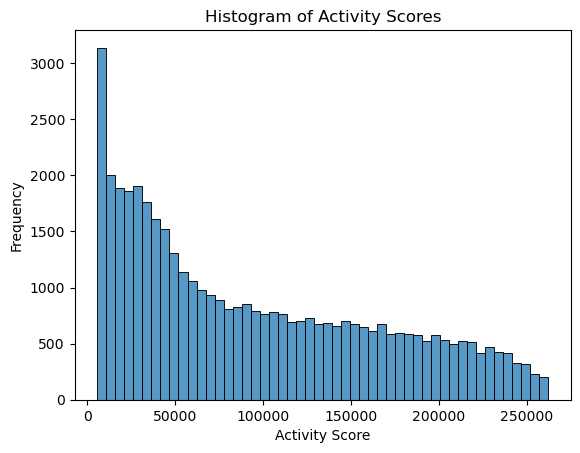

In [13]:
## Graphing Activity
sns.histplot(data=activities, x='Activity', bins=50, kde=False)
plt.xlabel('Activity Score')
plt.ylabel('Frequency')
plt.title('Histogram of Activity Scores')
plt.savefig(f'{dir}/Figs/{name}_ActivityScoreDist.jpg')
plt.show()

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


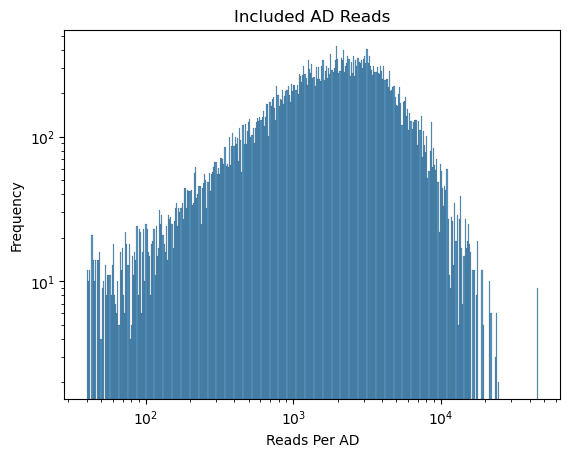

In [14]:
## Graphing AD reads

sns.histplot(data=total_reads_df, x='numreads_per_AD', bins=400, log_scale=(True, True))
plt.xlabel('Reads Per AD')
plt.ylabel('Frequency')
plt.title('Included AD Reads')
plt.savefig(f'{dir}/Figs/{name}_ADReadsDist.jpg')
plt.show()

/global/software/rocky-8.x86_64/manual/modules/langs/anaconda3/2024.02-1/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


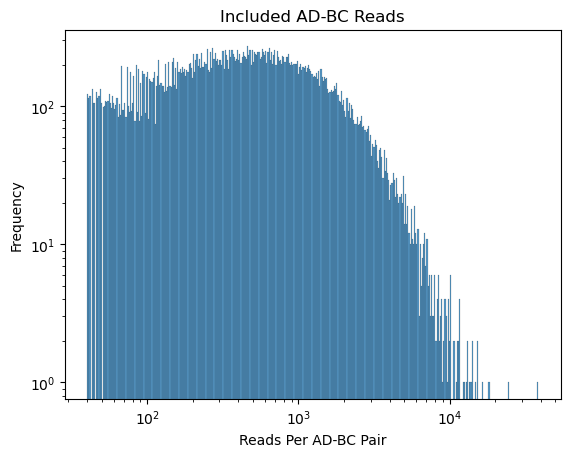

In [15]:
## Graphing AD-BC reads

sns.histplot(data=total_reads_df, x='Reads', bins=400, log_scale=(True, True))
plt.xlabel('Reads Per AD-BC Pair')
plt.ylabel('Frequency')
plt.title('Included AD-BC Reads')
plt.savefig(f'{dir}/Figs/{name}_ADBCReadsDist.jpg')
plt.show()